In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("../data/raw/payload_full.csv")
df.head()

,payload,length,attack_type,label
0,c/ caridad s/n,14,norm,norm
1,"campello, el",12,norm,norm
2,40184,5,norm,norm
3,1442431887503330,16,norm,norm
4,nue37,5,norm,norm


In [2]:
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nDataset information:")
df.info()
print("\nMissing values:")
print(df.isnull().sum())
print("\nClass distribution:")
print(df["label"].value_counts())
print("\nClass percentages:")
print(df["label"].value_counts(normalize=True) * 100)


Dataset shape: (31067, 4)

Columns:
['payload', 'length', 'attack_type', 'label']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 31067 entries, 0 to 31066
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   payload      31067 non-null  str  
 1   length       31067 non-null  int64
 2   attack_type  31067 non-null  str  
 3   label        31067 non-null  str  
dtypes: int64(1), str(3)
memory usage: 971.0 KB

Missing values:
payload        0
length         0
attack_type    0
label          0
dtype: int64

Class distribution:
label
norm    19304
anom    11763
Name: count, dtype: int64

Class percentages:
label
norm    62.136672
anom    37.863328
Name: proportion, dtype: float64


In [3]:
print("Attack type distribution:")
print(df["attack_type"].value_counts())

print("\nAttack type percentages:")
print(df["attack_type"].value_counts(normalize=True) * 100)

print("\nLabel and attack type relationship:")
print(pd.crosstab(df["label"], df["attack_type"]))

Attack type distribution:
attack_type
norm              19304
sqli              10852
xss                 532
path-traversal      290
cmdi                 89
Name: count, dtype: int64

Attack type percentages:
attack_type
norm              62.136672
sqli              34.930956
xss                1.712428
path-traversal     0.933466
cmdi               0.286478
Name: proportion, dtype: float64

Label and attack type relationship:
attack_type  cmdi   norm  path-traversal   sqli  xss
label                                               
anom           89      0             290  10852  532
norm            0  19304               0      0    0


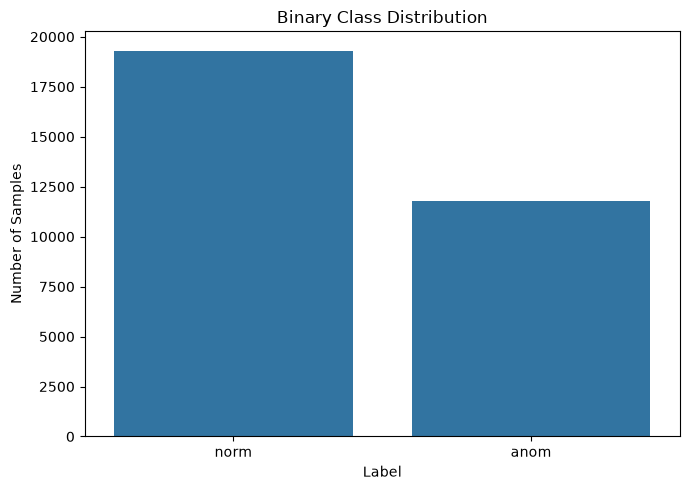

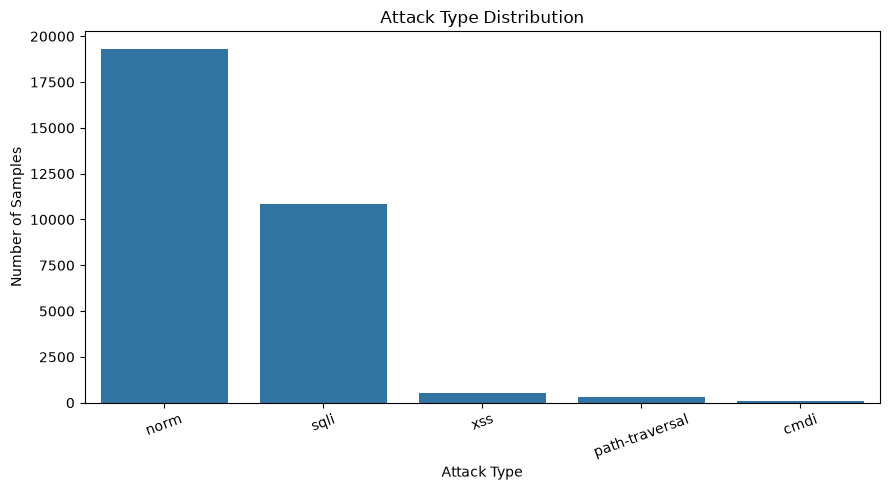

In [4]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="label")

plt.title("Binary Class Distribution")
plt.xlabel("Label")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="attack_type",
    order=df["attack_type"].value_counts().index
)

plt.title("Attack Type Distribution")
plt.xlabel("Attack Type")
plt.ylabel("Number of Samples")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [6]:
class_distribution = df["attack_type"].value_counts()

print("Class distribution:")
print(class_distribution)

print("\nMinimum class size:")
print(class_distribution.min())

print("\nClass proportions:")
print(df["attack_type"].value_counts(normalize=True) * 100)

Class distribution:
attack_type
norm              19304
sqli              10852
xss                 532
path-traversal      290
cmdi                 89
Name: count, dtype: int64

Minimum class size:
89

Class proportions:
attack_type
norm              62.136672
sqli              34.930956
xss                1.712428
path-traversal     0.933466
cmdi               0.286478
Name: proportion, dtype: float64


In [7]:
from sklearn.model_selection import train_test_split

X = df["payload"]
y = df["attack_type"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set size:", len(X_train))
print("Testing set size:", len(X_test))

print("\nTraining set class distribution:")
print(y_train.value_counts())

print("\nTesting set class distribution:")
print(y_test.value_counts())

Training set size: 24853
Testing set size: 6214

Training set class distribution:
attack_type
norm              15443
sqli               8681
xss                 426
path-traversal      232
cmdi                 71
Name: count, dtype: int64

Testing set class distribution:
attack_type
norm              3861
sqli              2171
xss                106
path-traversal      58
cmdi                18
Name: count, dtype: int64


In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [9]:
tfidf = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    min_df=2,
    max_features=50000
)

In [10]:
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training feature matrix:", X_train_tfidf.shape)
print("Testing feature matrix:", X_test_tfidf.shape)

Training feature matrix: (24853, 50000)
Testing feature matrix: (6214, 50000)


In [11]:
from sklearn.linear_model import LogisticRegression

baseline_model = LogisticRegression(
    max_iter=1000
)

baseline_model.fit(X_train_tfidf, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [12]:
y_pred_baseline = baseline_model.predict(X_test_tfidf)

print("Predictions completed!")
print("Number of predictions:", len(y_pred_baseline))

Predictions completed!
Number of predictions: 6214


In [13]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

print("Accuracy:", accuracy_score(y_test, y_pred_baseline))

print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred_baseline))

print("Macro F1:", f1_score(y_test, y_pred_baseline, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_baseline, digits=4, zero_division=0))

Accuracy: 0.994528484068233
Balanced Accuracy: 0.8612151160933882
Macro F1: 0.912086859052138

Classification Report:
                precision    recall  f1-score   support

          cmdi     1.0000    0.5000    0.6667        18
          norm     0.9915    0.9997    0.9956      3861
path-traversal     1.0000    0.9138    0.9550        58
          sqli     0.9995    0.9963    0.9979      2171
           xss     1.0000    0.8962    0.9453       106

      accuracy                         0.9945      6214
     macro avg     0.9982    0.8612    0.9121      6214
  weighted avg     0.9946    0.9945    0.9942      6214



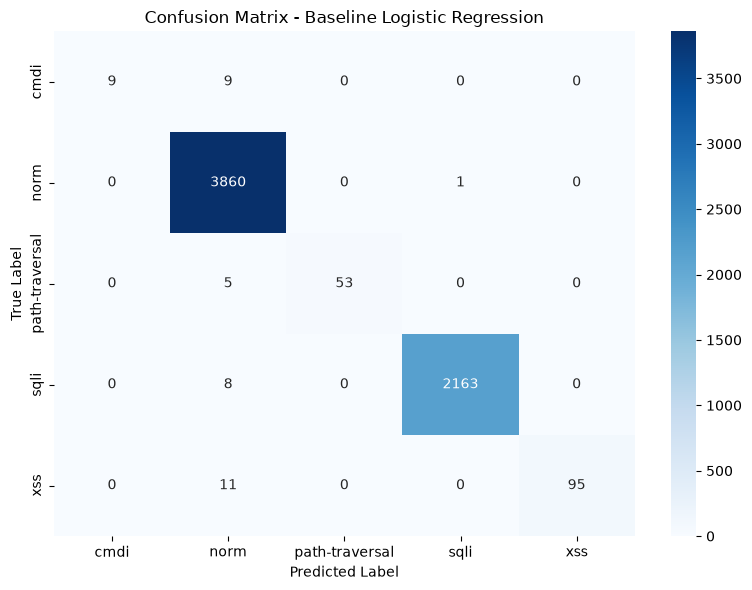

In [14]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

class_names = baseline_model.classes_

cm = confusion_matrix(
    y_test,
    y_pred_baseline,
    labels=class_names
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Baseline Logistic Regression")
plt.tight_layout()
plt.show()

In [15]:
import os
import pandas as pd
from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    y_pred_baseline,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

class_metrics = report_df.loc[
    ["cmdi", "norm", "path-traversal", "sqli", "xss"],
    ["precision", "recall", "f1-score", "support"]
]

class_metrics = class_metrics.round(4)

class_metrics.columns = [
    "Precision",
    "Recall",
    "F1-Score",
    "Support"
]

os.makedirs("../reports", exist_ok=True)

class_metrics.to_csv(
    "../reports/classification_metrics.csv",
    index_label="Attack Type",
    sep=",",
    encoding="utf-8"
)

print("=" * 65)
print("CLASS-WISE EVALUATION METRICS")
print("=" * 65)

print(class_metrics.to_string())

print("=" * 65)
print("\nClassification metrics saved successfully!")

CLASS-WISE EVALUATION METRICS
                Precision  Recall  F1-Score  Support
cmdi               1.0000  0.5000    0.6667     18.0
norm               0.9915  0.9997    0.9956   3861.0
path-traversal     1.0000  0.9138    0.9550     58.0
sqli               0.9995  0.9963    0.9979   2171.0
xss                1.0000  0.8962    0.9453    106.0

Classification metrics saved successfully!


In [16]:
import os
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

baseline_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Macro F1"
    ],
    "Score": [
        accuracy_score(y_test, y_pred_baseline),
        balanced_accuracy_score(y_test, y_pred_baseline),
        f1_score(y_test, y_pred_baseline, average="macro")
    ]
})

os.makedirs("../reports", exist_ok=True)

baseline_results.to_csv(
    "../reports/baseline_metrics.csv",
    index=False
)

print("Baseline Evaluation Metrics:")
print(baseline_results.to_string(index=False))

print("\nBaseline metrics saved successfully!")

Baseline Evaluation Metrics:
           Metric    Score
         Accuracy 0.994528
Balanced Accuracy 0.861215
         Macro F1 0.912087

Baseline metrics saved successfully!


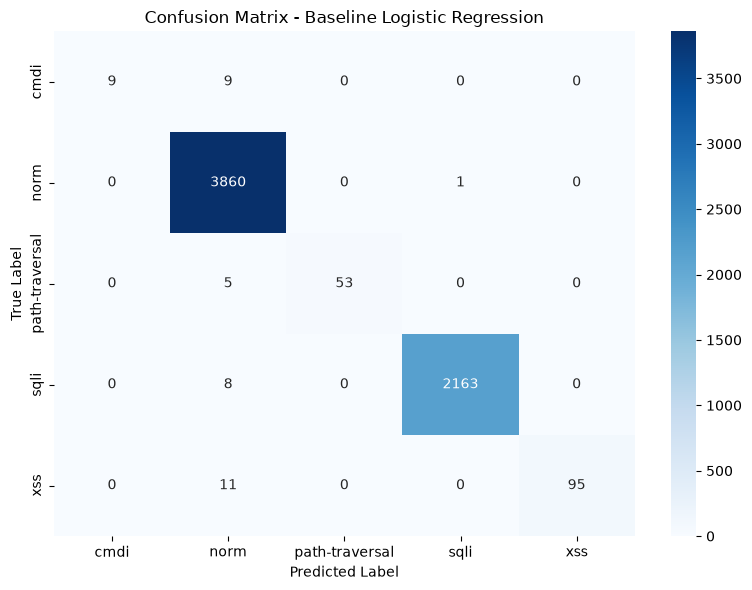

Confusion Matrix saved successfully!


In [17]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

class_names = baseline_model.classes_

cm = confusion_matrix(
    y_test,
    y_pred_baseline,
    labels=class_names
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Baseline Logistic Regression")
plt.tight_layout()

os.makedirs("../reports/figures", exist_ok=True)

plt.savefig(
    "../reports/figures/confusion_matrix_baseline.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion Matrix saved successfully!")